# RQ07 — sensibilidade das definições operacionais (Issue #68)

Esta análise mede quanto a classificação DORA muda entre três combinações: **C1** (*release*, lead time a, CFR a), **C2** (*release* + pré-*release*, lead time b, CFR b) e **C3** (*tag*, lead time b, CFR a). O tempo de recuperação é o mesmo nas três. A categoria geral é a mediana das notas das métricas disponíveis, arredondada para baixo.

In [1]:
from itertools import combinations
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALISE = Path.cwd()
CODE = ANALISE.parent / 'code'
sys.path.insert(0, str(CODE))
from metrics.sensibilidade import (
    ORDEM_CATEGORIAS, classificar_combinacao, comparar_classificacoes,
)

FIGURAS = ANALISE / 'figuras'
TABELAS = ANALISE / 'tabelas'
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / 'data' / 'dataset_dora.csv')
assert df['full_name'].is_unique, 'full_name precisa ser uma chave única'
print(f'{len(df)} repositórios')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\MatheusGastonVianaSi\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


300 repositórios


## Classificação C1, C2 e C3

In [2]:
COMBINACOES = {
    'C1': {
        'deploy_frequency': 'deploy_freq_release',
        'lead_time': 'lead_time_a_horas',
        'cfr': 'cfr_a',
        'tempo_recuperacao': 'tempo_recuperacao_horas',
    },
    'C2': {
        'deploy_frequency': 'deploy_freq_release_pre',
        'lead_time': 'lead_time_b_horas',
        'cfr': 'cfr_b',
        'tempo_recuperacao': 'tempo_recuperacao_horas',
    },
    'C3': {
        'deploy_frequency': 'deploy_freq_tag',
        'lead_time': 'lead_time_b_horas',
        'cfr': 'cfr_a',
        'tempo_recuperacao': 'tempo_recuperacao_horas',
    },
}

def valor(v):
    return None if pd.isna(v) else float(v)

classificacoes = df[['full_name']].copy()
for nome, colunas in COMBINACOES.items():
    categorias = pd.DataFrame(
        [
            classificar_combinacao(*(valor(r[c]) for c in colunas.values()))
            for _, r in df.iterrows()
        ],
        index=df.index,
    ).add_prefix(f'{nome.lower()}_')
    classificacoes = pd.concat([classificacoes, categorias], axis=1)

# C1 deve reproduzir exatamente as colunas já geradas pelo dataset.
for metrica in ('deploy_frequency', 'lead_time', 'cfr', 'tempo_recuperacao', 'geral'):
    assert (
        classificacoes[f'c1_{metrica}'].fillna('-')
        == df[f'c1_{metrica}'].fillna('-')
    ).all(), metrica

classificacoes.to_csv(CODE / 'data' / 'classificacao_rq07.csv', index=False)
print('C1 conferida com o dataset; C1, C2 e C3 exportadas para classificacao_rq07.csv')
classificacoes.head()

C1 conferida com o dataset; C1, C2 e C3 exportadas para classificacao_rq07.csv


,full_name,c1_deploy_frequency,c1_lead_time,c1_cfr,c1_tempo_recuperacao,c1_geral,c2_deploy_frequency,c2_lead_time,c2_cfr,c2_tempo_recuperacao,c2_geral,c3_deploy_frequency,c3_lead_time,c3_cfr,c3_tempo_recuperacao,c3_geral
0,917Dhj/DeepPaperNote,Medium,High,Elite,Elite,High,Medium,High,Elite,Elite,High,Medium,High,Elite,Elite,High
1,AcademySoftwareFoundation/openexr,Medium,Low,Elite,Medium,Medium,Medium,Low,Elite,Medium,Medium,High,Low,Elite,Medium,Medium
2,Agents365-ai/drawio-skill,Medium,Elite,High,Elite,High,Medium,Elite,High,Elite,High,Medium,Elite,High,Elite,High
3,Aidoku/Aidoku,Low,Low,Elite,High,Medium,Low,Medium,Elite,High,Medium,Low,Medium,Elite,High,Medium
4,AndyHazz/bookshelf.koplugin,High,Elite,Elite,Medium,High,High,Elite,Low,Medium,Medium,High,Elite,Elite,Medium,High


## Distribuição das categorias gerais

In [3]:
distribuicao = pd.DataFrame({
    nome: classificacoes[f'{nome.lower()}_geral'].value_counts().reindex(ORDEM_CATEGORIAS, fill_value=0)
    for nome in COMBINACOES
}).T
distribuicao.index.name = 'combinacao'
distribuicao['total'] = distribuicao.sum(axis=1)
distribuicao.to_csv(TABELAS / 'rq07_distribuicao_combinacoes.csv')
distribuicao

,Elite,High,Medium,Low,total
combinacao,,,,,
C1,17,125,137,21,300
C2,10,119,155,16,300
C3,27,138,119,16,300


## Mudança de categoria e kappa ponderado

O kappa recebe explicitamente a ordem `Elite → High → Medium → Low`. Sem isso, o sklearn ordenaria os rótulos alfabeticamente e atribuiria distâncias erradas entre as categorias.

In [4]:
linhas = []
for a, b in combinations(COMBINACOES, 2):
    resultado = comparar_classificacoes(
        classificacoes[f'{a.lower()}_geral'].where(lambda s: s.notna(), None),
        classificacoes[f'{b.lower()}_geral'].where(lambda s: s.notna(), None),
    )
    linhas.append({'comparacao': f'{a} × {b}', **resultado})

pares = pd.DataFrame(linhas)
pares.to_csv(TABELAS / 'rq07_pares.csv', index=False)
pares

,comparacao,n_repositorios,n_mudaram,percentual_mudanca,kappa_ponderado_linear,n_mudancas_adjacentes,n_mudancas_distantes
0,C1 × C2,300,113,37.666667,0.431999,107,6
1,C1 × C3,300,90,30.000000,0.593819,88,2
2,C2 × C3,300,65,21.666667,0.682895,61,4


## Matrizes de transição

In [5]:
matrizes = {}
for a, b in combinations(COMBINACOES, 2):
    matriz = pd.crosstab(
        pd.Categorical(classificacoes[f'{a.lower()}_geral'], ORDEM_CATEGORIAS, ordered=True),
        pd.Categorical(classificacoes[f'{b.lower()}_geral'], ORDEM_CATEGORIAS, ordered=True),
        rownames=[a], colnames=[b], dropna=False,
    ).reindex(index=ORDEM_CATEGORIAS, columns=ORDEM_CATEGORIAS, fill_value=0)
    matrizes[(a, b)] = matriz
    matriz.to_csv(TABELAS / f'rq07_transicao_{a.lower()}_{b.lower()}.csv')

matrizes[('C1', 'C2')]

C2,Elite,High,Medium,Low
C1,,,,
Elite,5,9,3,0
High,4,75,44,2
Medium,1,35,97,4
Low,0,0,11,10


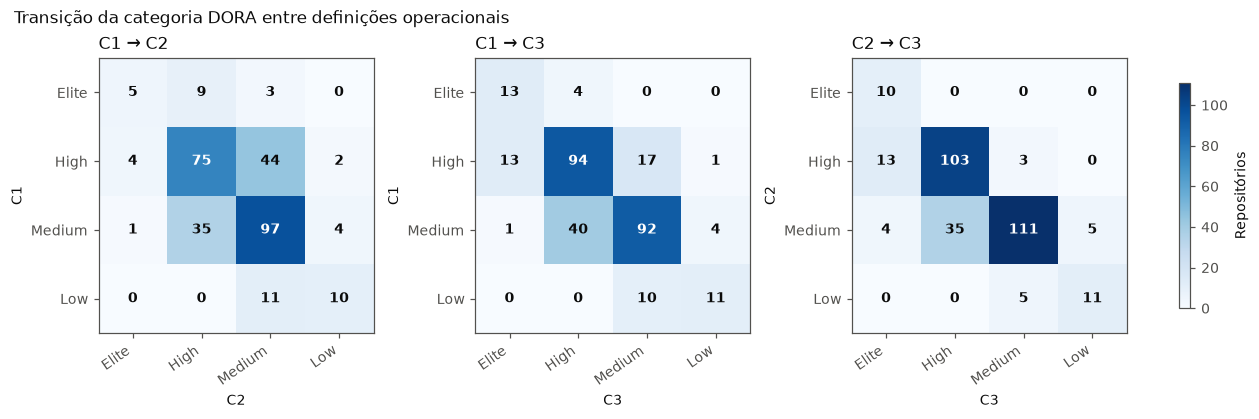

In [6]:
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 9,
    'axes.edgecolor': TEXTO_2, 'axes.labelcolor': TEXTO, 'text.color': TEXTO,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
})

fig, eixos = plt.subplots(1, 3, figsize=(11.4, 3.7), layout='constrained')
maximo = max(matriz.to_numpy().max() for matriz in matrizes.values())
imagem = None
for ax, ((a, b), matriz) in zip(eixos, matrizes.items()):
    valores = matriz.to_numpy()
    imagem = ax.imshow(valores, cmap='Blues', vmin=0, vmax=maximo)
    ax.set_xticks(range(4), ORDEM_CATEGORIAS, rotation=35, ha='right')
    ax.set_yticks(range(4), ORDEM_CATEGORIAS)
    ax.set_xlabel(b)
    ax.set_ylabel(a)
    ax.set_title(f'{a} → {b}', loc='left')
    for i in range(4):
        for j in range(4):
            valor_celula = int(valores[i, j])
            cor = 'white' if valor_celula > maximo * 0.55 else TEXTO
            ax.text(j, i, str(valor_celula), ha='center', va='center', color=cor, fontweight='bold')
fig.colorbar(imagem, ax=eixos, label='Repositórios', shrink=0.82)
fig.suptitle('Transição da categoria DORA entre definições operacionais', x=0.01, ha='left')
fig.savefig(FIGURAS / 'rq07_matrizes_transicao.png')

## Síntese

A classificação é sensível, mas as mudanças são predominantemente locais na escala ordinal. C1 × C2 é o par mais instável: 37,7% dos repositórios mudam e o kappa é 0,432. C1 × C3 tem 30,0% de mudanças e kappa 0,594; C2 × C3, 21,7% e kappa 0,683. Em C1 × C2, 107 das 113 mudanças são entre categorias vizinhas e não há transição direta Elite ↔ Low. O retrato agregado permanece concentrado em Medium/High, embora o rótulo de um repositório individual dependa materialmente da definição.